# Example 3: the target structures deployed with the ribbon model

Every target of example 1 is sliced and cut in the same way. The beams are read from its cutting pattern, and the centre of the pattern (the centre of the top contour) is moved up to the height of its contour line. This is deployment by displacement, with the force as an unknown. Every level is then compared with the height of its contour line on the target.

Run the notebook from the `examples/` folder. The script `03_ribbon_targets.py` does the same.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore", category = RuntimeWarning)   # fsolve progress warnings of the section lines
import os, importlib
import numpy as np
from common import *   # also puts ../lib on the path
from ribbon_model import beams_from_pattern, RibbonModel
example2 = importlib.import_module('02_ribbon_model')    # draw_sheet
example3 = importlib.import_module('03_ribbon_targets')  # deploy_target, level_heights

TARGETS = ['cone', 'parabole', 'offcenter', 'trumpet', 'free_curve']
LEVELS, TOP, N = 15, 0.9, 6
YOUNG, THICKNESS = 2100.0, 0.1   # MPa, mm
out = output_dir('03_ribbon_targets')

## Deployment and level heights

For every level, the cut contour moved by the level gives a mean height and the spread along the contour (min to max). A tilted level has a large spread.

cone       14 levels, force 1.859 N, level height error rms 0.05 mm of 39.5 mm, largest tilt 0.6 deg


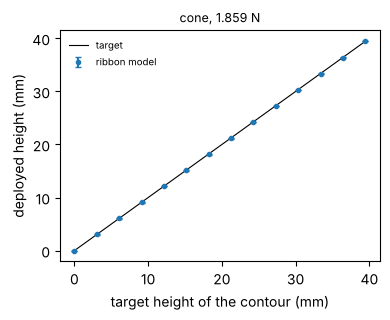

parabole   14 levels, force 1.832 N, level height error rms 0.34 mm of 59.2 mm, largest tilt 1.0 deg


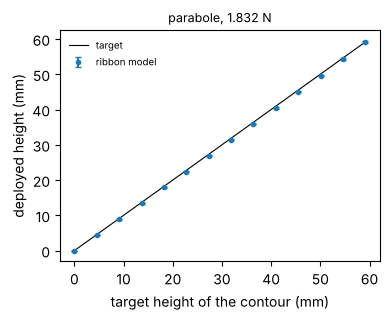

offcenter  14 levels, force 1.816 N, level height error rms 0.11 mm of 8.8 mm, largest tilt 6.4 deg


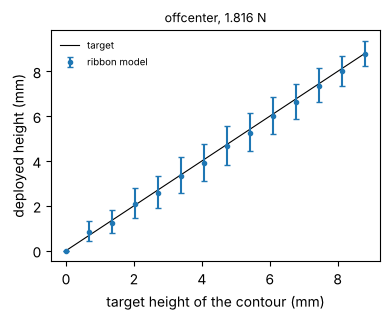

trumpet    14 levels, force 2.061 N, level height error rms 0.52 mm of 78.9 mm, largest tilt 3.7 deg


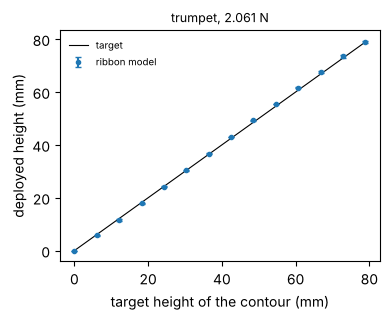

free_curve 14 levels, force 1.874 N, level height error rms 0.90 mm of 19.2 mm, largest tilt 28.7 deg


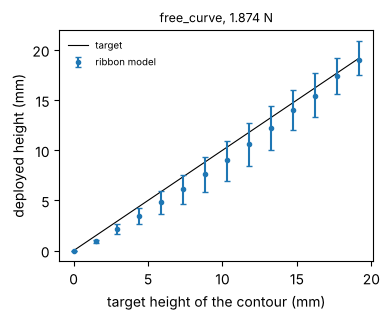

In [2]:
results = {}
for name in TARGETS:
    sheet, lines, spans, model, q, force, target = example3.deploy_target(name, LEVELS, TOP, N, YOUNG, THICKNESS)
    z = example3.level_heights(lines, q)
    t = target[:model.n_levels]
    err = z[:, 0]-t
    tilt = np.degrees(np.hypot(q[:, 1], q[:, 2]))
    results[name] = (sheet, lines, spans, model, q, force)
    print('%-10s %2d levels, force %.3f N, level height error rms %.2f mm of %.1f mm, largest tilt %.1f deg' % (
          name, model.n_levels, force, np.sqrt(np.mean(err**2)), t[-1], tilt.max()))
    fig, ax = plt.subplots(figsize = (4, 3.3))
    ax.plot(t, t, 'k-', lw = 0.8, label = 'target')
    ax.errorbar(t, z[:, 0], yerr = [z[:, 0]-z[:, 1], z[:, 2]-z[:, 0]], fmt = 'o', ms = 3, capsize = 2, label = 'ribbon model')
    ax.set_xlabel('target height of the contour (mm)'); ax.set_ylabel('deployed height (mm)')
    ax.set_title('%s, %.3f N' % (name, force), fontsize = 9)
    ax.legend(frameon = False, fontsize = 7)
    fig.tight_layout()
    finish(fig, os.path.join(out, name+'_levels.png'))

## Deployed sheets

The cut sheet moved by the model, also written as `output/03_ribbon_targets/<name>_ribbon.obj`. Change `NAME` to view another target.

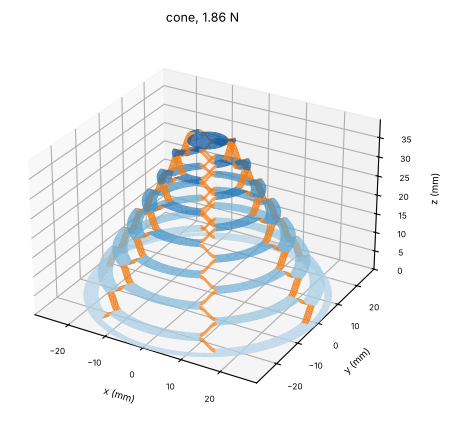

In [3]:
NAME = 'cone'
for name, (sheet, lines, spans, model, q, force) in results.items():
    V, F = sheet['V'], sheet['F']
    part, coord = model.classify(V, F, lines, spans)
    X = model.deform(V, F, part, coord, q)
    igl.write_triangle_mesh(os.path.join(out, name+'_ribbon.obj'), X, F)
    if name == NAME:
        fig = plt.figure(figsize = (6, 5))
        example2.draw_sheet(fig.add_subplot(projection = '3d'), X, F, part, model.n_levels, '%s, %.2f N' % (name, force))
        finish(fig, os.path.join(out, name+'_3d.png'))